<a href="https://colab.research.google.com/github/amandassr/claro-plan-compass/blob/main/Projeto_1_Recomendador_de_Planos_COLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto 1 — Recomendador de planos por perfil de uso

**Recorte escolhido:** *Excesso de consumo* (com apoio de *Equilíbrio entre preço e adequação*).

> 📘 **Como usar este notebook (passo a passo para quem está começando)**
> 1. No Colab, clique em **Conectar** (canto superior direito).
> 2. Abra a pasta 📁 **Arquivos** (barra da esquerda) e envie o CSV do projeto (`P1_...csv`). Se esquecer, a Etapa 2 abre uma janela pedindo o upload.
> 3. Execute as células **de cima para baixo** (botão ▶ de cada célula) ou use **Ambiente de execução → Executar tudo**.
> 4. Leia o texto que vem *antes* de cada célula: ele explica **o que** o código faz, **por que** faz e **o que observar** no resultado.

### Mapa do notebook

| Etapa | O que acontece | Para que serve |
|---|---|---|
| 1 | Planejamento | Pergunta de pesquisa, hipóteses, baseline, melhoria e indicadores |
| 2 | Carregar dados | Ler o CSV para dentro do Python |
| 3 | Limpar | Corrigir valores sujos (ex.: `"24 GB"`, `"não informado"`) |
| 4 | Catálogo | Lista (fictícia) de planos que podem ser recomendados |
| 5 | Explorar | Entender os clientes e o tamanho do problema de excesso |
| 6 | Baseline | Regra simples para ter com o que comparar |
| 7 | Modelo melhorado | Regra com pesos, penalidades, margem para picos e preço |
| 8 | Experimentos | Testar as hipóteses e medir se melhorou |
| 9 | Estabilidade e riscos | Ver se a recomendação é robusta e justa |
| 10 | Explicação + interface | Texto em português para o cliente e protótipo de tela |
| 11 | Conclusões | Responder à pergunta de pesquisa |
| 12 | Apresentação | Roteiro dos 10 minutos |

> ⚠️ Todos os dados e planos são **fictícios** e o resultado é uma **simulação educacional**.

## Etapa 1 — Planejamento (antes de programar)

**Por que começar aqui?** Sem uma pergunta clara, qualquer número parece "resultado". Planejar primeiro evita escolher a conclusão depois de ver os dados.

### Pequeno glossário
- **Franquia:** quanto o plano oferece (ex.: 25 GB de internet). Se o cliente usa mais que a franquia, há **excesso**.
- **Baseline:** regra simples usada só como *ponto de comparação*. Se o modelo novo não ganhar dela, a "melhoria" não vale nada.
- **Score:** nota que o modelo dá a cada plano. **Quanto menor, melhor** (o plano é mais "próximo" do que o cliente precisa).
- **Penalidade:** multiplicador que torna um erro mais "caro" no score. Aqui, faltar franquia custa mais que sobrar.
- **Top-3:** as três melhores recomendações para cada cliente.

### Pergunta de pesquisa
> Em uma base de clientes cujo consumo tende a passar da franquia, **como penalizar a falta de franquia, aplicar uma margem para picos de consumo e incluir o preço** modifica a qualidade (cobertura e custo) das três recomendações, em comparação com uma regra simples baseada só em GB?

### Hipóteses (testáveis)
- **H1 — preço:** incluir o preço no score **reduz o preço médio** recomendado, mas pode **aumentar** a proporção de planos insuficientes (conflito entre métricas).
- **H2 — penalidade:** aumentar a penalidade por falta de franquia **reduz a proporção de recomendações insuficientes** em dados.
- **H3 — picos:** aplicar uma margem de segurança sobre o consumo (ex.: +10%) **reduz as insuficiências** em relação a não ter margem, ao custo de um preço médio maior.

### Regra inicial (baseline)
Recomendar os 3 planos cuja franquia de **GB** é **mais próxima** do consumo do cliente (ignora preço, minutos, streaming e deslocamento).

### Melhoria planejada
Score que combina **dados, minutos, streaming e deslocamento** (com pesos), **penalidade maior para faltar** do que para sobrar, **margem para picos** e **termo de preço**.

### Indicadores de comparação
1. Preço médio recomendado (R$) e diferença em relação ao plano atual.
2. % de clientes que **economizam** e % que **pagam mais**.
3. % de recomendações com **franquia de dados insuficiente** (top-1 e top-3) e com insuficiência em **qualquer** dimensão.
4. **Estabilidade** da recomendação ao mudar pesos e consumo.
5. **Métrica complementar do grupo:** comportamento entre clientes com `risco_cancelamento = 1`.

> Estes são indicadores de laboratório: **não** provam satisfação real de clientes.

## Etapa 2 — Carregar os dados

**O que acontece:** o Python precisa do arquivo CSV *dentro do Colab*. O código procura arquivos que comecem com `P1` ou `Projeto_1`. Se não achar, abre uma janela de upload.

**Detalhes importantes**
- `encoding='utf-8-sig'` remove um caractere invisível (BOM) que vinha grudado no nome da primeira coluna (`id_cliente`).
- Se houver vários CSVs, escreva o nome exato em `NOME_CSV`.
- Ao reiniciar o Colab, o arquivo some: envie de novo.
- **Observação:** os dois CSVs que você tem (`P1_ 2.csv` e `Projeto_1_Recomendador_de_Planos_Excesso_de_Consumo.csv`) têm **exatamente o mesmo conteúdo**; pode usar qualquer um.

**O que observar na saída:** 240 linhas, 11 colunas, e `dados_gb` aparecendo como `object` (texto) — isso é um **alerta**: deveria ser número.

In [ ]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)

# Se quiser forçar um arquivo, escreva o nome aqui. Exemplo: NOME_CSV = 'P1_ 2.csv'
NOME_CSV = None

def achar_csvs():
    achados = []
    for pasta in [Path('.'), Path('/content')]:
        if pasta.exists():
            achados += [p for p in pasta.glob('*.csv') if p.name.startswith(('P1', 'Projeto_1'))]
    unicos, vistos = [], set()
    for p in achados:
        r = p.resolve()
        if r not in vistos:
            vistos.add(r)
            unicos.append(p)
    return sorted(unicos)

candidatos = achar_csvs()
if NOME_CSV is None and not candidatos:
    try:
        from google.colab import files
        print('Nenhum CSV do Projeto 1 encontrado. Selecione o arquivo CSV:')
        enviados = files.upload()
        candidatos = [Path(n) for n in enviados if n.lower().endswith('.csv')]
    except ImportError:
        raise FileNotFoundError('Coloque o CSV na mesma pasta do notebook ou escreva o nome em NOME_CSV.')

caminho = Path(NOME_CSV) if NOME_CSV else candidatos[0]
print('Pasta de trabalho:', os.getcwd())
print('Arquivo usado   :', caminho)

df_bruto = pd.read_csv(caminho, encoding='utf-8-sig')
print('Linhas e colunas:', df_bruto.shape)
display(df_bruto.head())
print(df_bruto.dtypes)

Nenhum CSV do Projeto 1 encontrado. Selecione o arquivo CSV:


Saving P1_ (2).csv to P1_ (2).csv
Pasta de trabalho: /content
Arquivo usado   : P1_ (2).csv
Linhas e colunas: (240, 11)


,id_cliente,idade_faixa,regiao,dados_gb,minutos,streaming_horas,deslocamento_dias,plano_atual,mensalidade_atual,risco_cancelamento,perfil_grupo
0,20001,41-60,rural,36.1,569,13.5,8,Essencial,39.9,1,Franquia insuficiente
1,20002,18-25,rural,46.5,660,13.7,5,Max,109.9,0,Franquia insuficiente
2,20003,60+,rural,40.4,649,16.4,7,Flex,69.9,1,Franquia insuficiente
3,20004,26-40,rural,31.9,633,21.7,2,Digital,84.9,0,Franquia insuficiente
4,20005,18-25,urbana,48.5,527,10.1,6,Conecta,54.9,1,Franquia insuficiente


id_cliente              int64
idade_faixa            object
regiao                 object
dados_gb               object
minutos                 int64
streaming_horas       float64
deslocamento_dias       int64
plano_atual            object
mensalidade_atual     float64
risco_cancelamento      int64
perfil_grupo           object
dtype: object


## Etapa 3 — Compreender e limpar

**Unidades dos quatro atributos de uso**

| Coluna | Unidade | Faixa plausível adotada |
|---|---|---|
| `dados_gb` | GB por mês | 0 a 300 |
| `minutos` | minutos de ligação por mês | 0 a 5000 |
| `streaming_horas` | horas de streaming por mês | 0 a 200 |
| `deslocamento_dias` | dias por mês em deslocamento/viagem | 0 a 31 |

**Problema encontrado:** `dados_gb` foi lido como *texto* porque algumas linhas têm `"24 GB"`, `"não informado"` ou estão vazias. Se tentássemos `float("24 GB")` o programa **quebraria**; e comparar um valor vazio (`NaN`) com a franquia daria resultado errado sem avisar.

**Decisões de limpeza (registre no relatório!)**
1. `"24 GB"` → `24.0` (extraímos o número).
2. `"não informado"` e vazio → ausente. Como é só **1 cliente**, substituímos pela **mediana** dos demais e marcamos a linha em `dados_imputado = True`, para poder auditar depois.
3. Conferimos negativos e valores fora das faixas plausíveis (*outliers*).

> **Por que preço não deve ser misturado direto com GB?** Porque as unidades e escalas são diferentes (R$ de 40 a 150 versus GB de 8 a 90). O número maior "esmagaria" o menor. Por isso depois **dividimos tudo por uma escala comum** (normalização).

In [ ]:
COLS_USO = ['dados_gb', 'minutos', 'streaming_horas', 'deslocamento_dias']

df = df_bruto.copy()
df.columns = df.columns.str.strip()

# 3.1 Quais valores de dados_gb não são número puro?
convertido = pd.to_numeric(df['dados_gb'], errors='coerce')
print('Valores problemáticos em dados_gb:')
display(df.loc[convertido.isna(), ['id_cliente', 'dados_gb']])

# 3.2 Função de limpeza
def limpar_gb(valor):
    """'24 GB' -> 24.0 ; '36.1' -> 36.1 ; 'não informado' / vazio -> NaN"""
    if pd.isna(valor):
        return np.nan
    texto = str(valor).strip().lower().replace(',', '.')
    achado = re.search(r'\d+(\.\d+)?', texto)
    return float(achado.group()) if achado else np.nan

df['dados_gb'] = df['dados_gb'].map(limpar_gb)
df['dados_imputado'] = df['dados_gb'].isna()
mediana_gb = df['dados_gb'].median()
df['dados_gb'] = df['dados_gb'].fillna(mediana_gb)
print(f'\nClientes com dados_gb imputado pela mediana ({mediana_gb:.1f} GB):', int(df['dados_imputado'].sum()))

# 3.3 Verificações de qualidade
limites = {'dados_gb': (0, 300), 'minutos': (0, 5000), 'streaming_horas': (0, 200), 'deslocamento_dias': (0, 31)}
assert df[COLS_USO].notna().all().all(), 'Ainda existem valores ausentes'
assert df[COLS_USO].ge(0).all().all(), 'Valores de uso negativos'
assert df['id_cliente'].is_unique, 'Há ids de cliente repetidos'
for c, (lo, hi) in limites.items():
    fora = ((df[c] < lo) | (df[c] > hi)).sum()
    print(f'{c:18s} fora da faixa plausível [{lo}, {hi}]: {fora}')

# Outliers estatísticos (regra do IQR), só para investigar, sem apagar nada
for c in COLS_USO:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f'{c:18s} possíveis outliers (IQR): {n_out}')

display(df[COLS_USO + ['mensalidade_atual']].describe().round(2))

Valores problemáticos em dados_gb:


,id_cliente,dados_gb
19,20020,NaN
86,20087,24 GB
175,20176,não informado



Clientes com dados_gb imputado pela mediana (44.2 GB): 2
dados_gb           fora da faixa plausível [0, 300]: 0
minutos            fora da faixa plausível [0, 5000]: 0
streaming_horas    fora da faixa plausível [0, 200]: 0
deslocamento_dias  fora da faixa plausível [0, 31]: 0
dados_gb           possíveis outliers (IQR): 0
minutos            possíveis outliers (IQR): 1
streaming_horas    possíveis outliers (IQR): 1
deslocamento_dias  possíveis outliers (IQR): 0


,dados_gb,minutos,streaming_horas,deslocamento_dias,mensalidade_atual
count,240.00,240.00,240.00,240.00,240.00
mean,44.62,545.46,15.93,5.22,90.63
std,12.35,74.35,3.92,2.85,33.81
min,11.30,340.00,5.20,0.00,39.90
25%,35.75,490.00,13.48,3.00,66.15
50%,44.20,546.00,15.80,5.00,92.40
75%,53.22,595.25,18.73,7.00,119.90
max,77.00,762.00,25.40,13.00,149.90


**Como ler:** a tabela `describe` mostra mínimo, média, quartis e máximo. Valores *estatisticamente* distantes (outliers pelo IQR) **não foram removidos**, pois ainda estão dentro de faixas plausíveis: um cliente que usa 77 GB é raro, mas possível — e é justamente o tipo de cliente que o recorte "excesso de consumo" quer atender.

## Etapa 4 — Catálogo fictício e auditável

O catálogo é a lista de planos que o modelo pode recomendar.

Incluímos o plano **Intenso**, porque a base tem clientes de até ~77 GB e o catálogo original tem um "buraco" entre **Max (55 GB)** e **Total (90 GB)**.

**Justificativa dos valores (interpolação linear entre Max e Total):**
| Atributo | Max | Total | Intenso (70 GB) |
|---|---|---|---|
| Dados (GB) | 55 | 90 | **70** |
| Minutos | 700 | 1100 | **850** |
| Streaming (h) | 18 | 28 | **22** |
| Deslocamento (dias) | 8 | 12 | **10** |
| Preço (R$) | 109,9 | 149,9 | **129,9** (interpolado ≈ 127, arredondado para cima) |

Para comparar com e sem o plano extra, mude `USAR_PLANO_EXTRA` para `False`.

In [ ]:
USAR_PLANO_EXTRA = True   # True = catálogo com o plano 'Intenso'; False = catálogo original

linhas_catalogo = [
    ['Essencial', 39.9,   8,  120,  2,  1], ['Conecta',   54.9,  15,  250,  4,  2],
    ['Flex',      69.9,  25,  350,  7,  4], ['Digital',   84.9,  35,  450, 12,  6],
    ['Max',      109.9,  55,  700, 18,  8], ['Total',    149.9,  90, 1100, 28, 12],
    ['Viagem',   119.9,  45,  550, 14, 20], ['Streaming', 99.9,  40,  350, 30,  5],
]
if USAR_PLANO_EXTRA:
    linhas_catalogo.append(['Intenso', 129.9, 70, 850, 22, 10])

CATALOGO = pd.DataFrame(linhas_catalogo,
                        columns=['plano', 'preco', 'dados_gb', 'minutos', 'streaming_horas', 'deslocamento_dias']
                        ).reset_index(drop=True)
display(CATALOGO)

# Escala comum para comparar GB, minutos, horas e dias: o maior valor do catálogo em cada coluna
ESCALA = CATALOGO[COLS_USO].max().to_dict()
print('Escala usada na normalização:', ESCALA)

# Conferência: todo plano_atual existe no catálogo e a mensalidade bate com o preço?
cat_idx = CATALOGO.set_index('plano')
assert df['plano_atual'].isin(cat_idx.index).all(), 'Há plano_atual que não existe no catálogo'
divergentes = (df['mensalidade_atual'] != df['plano_atual'].map(cat_idx['preco'])).sum()
print('Clientes cuja mensalidade difere do preço do catálogo:', divergentes)

,plano,preco,dados_gb,minutos,streaming_horas,deslocamento_dias
0,Essencial,39.9,8,120,2,1
1,Conecta,54.9,15,250,4,2
2,Flex,69.9,25,350,7,4
3,Digital,84.9,35,450,12,6
4,Max,109.9,55,700,18,8
5,Total,149.9,90,1100,28,12
6,Viagem,119.9,45,550,14,20
7,Streaming,99.9,40,350,30,5
8,Intenso,129.9,70,850,22,10


Escala usada na normalização: {'dados_gb': 90, 'minutos': 1100, 'streaming_horas': 30, 'deslocamento_dias': 20}
Clientes cuja mensalidade difere do preço do catálogo: 0


## Etapa 5 — Explorar: qual é o tamanho do problema de excesso?

**Ideia:** antes de recomendar, vamos medir **quantos clientes já estão com franquia insuficiente no plano atual**. Isso mostra se o recorte "excesso de consumo" faz sentido nesta base.

**Atenção a um detalhe:** a coluna `perfil_grupo` vale `"Franquia insuficiente"` para **todos** os 240 clientes. É um rótulo que veio no CSV; **não** é um cálculo nosso. Por isso conferimos se ele bate com o que calculamos comparando o consumo com a franquia do plano atual.

**O que observar**
- % de clientes cujo plano atual **não cobre** os dados (e em qualquer dimensão).
- Quais planos atuais concentram o excesso e o `risco_cancelamento`.
- No gráfico: as linhas tracejadas são as franquias de cada plano; clientes à direita de uma linha estouram aquele plano.

Clientes com dados acima da franquia do plano atual : 64.2%
Clientes acima da franquia em ALGUMA dimensão        : 81.7%

O rótulo perfil_grupo do CSV bate com o nosso cálculo?


excede_dados_atual,False,True,All
perfil_grupo,,,
Franquia insuficiente,86,154,240
All,86,154,240


,clientes,uso_medio_gb,franquia_gb,pct_excede_dados,risco_cancelamento_medio,mensalidade
plano_atual,,,,,,
Essencial,35,44.59,8,100.00,1.00,39.9
Conecta,25,43.96,15,100.00,0.80,54.9
Flex,30,45.97,25,90.00,0.40,69.9
Digital,30,42.19,35,70.00,0.20,84.9
Streaming,29,48.59,40,72.41,0.28,99.9
Max,25,43.82,55,16.00,0.12,109.9
Viagem,40,45.49,45,52.50,0.25,119.9
Total,26,41.53,90,0.00,0.19,149.9


regiao,rural,periferica,urbana
clientes,88,88,64


idade_faixa,18-25,60+,41-60,26-40
clientes,67,65,57,51


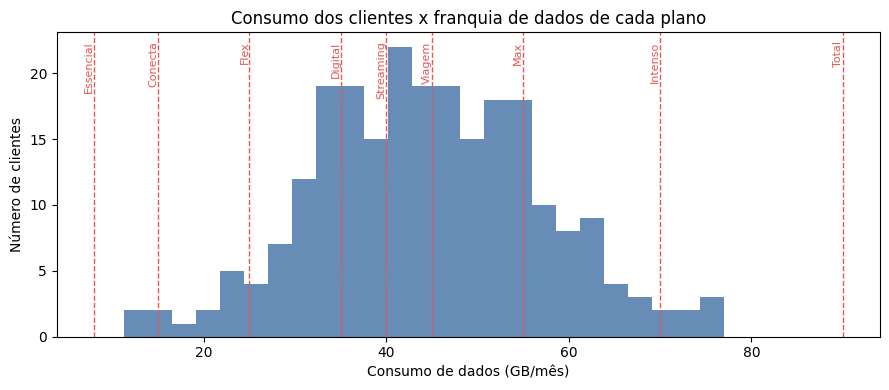

In [ ]:
# 5.1 Franquia do plano atual de cada cliente
for c in COLS_USO:
    df[c + '_franquia_atual'] = df['plano_atual'].map(cat_idx[c])

df['excede_dados_atual'] = df['dados_gb'] > df['dados_gb_franquia_atual']
df['excede_algum_atual'] = np.column_stack([df[c] > df[c + '_franquia_atual'] for c in COLS_USO]).any(axis=1)

print(f"Clientes com dados acima da franquia do plano atual : {df['excede_dados_atual'].mean():.1%}")
print(f"Clientes acima da franquia em ALGUMA dimensão        : {df['excede_algum_atual'].mean():.1%}")
print('\nO rótulo perfil_grupo do CSV bate com o nosso cálculo?')
display(pd.crosstab(df['perfil_grupo'], df['excede_dados_atual'], margins=True))

# 5.2 Resumo por plano atual
resumo_plano = df.groupby('plano_atual').agg(
    clientes=('id_cliente', 'count'),
    uso_medio_gb=('dados_gb', 'mean'),
    franquia_gb=('dados_gb_franquia_atual', 'first'),
    pct_excede_dados=('excede_dados_atual', lambda s: s.mean() * 100),
    risco_cancelamento_medio=('risco_cancelamento', 'mean'),
    mensalidade=('mensalidade_atual', 'first'),
).sort_values('mensalidade').round(2)
display(resumo_plano)

# 5.3 Perfil demográfico (usado só para auditar justiça, NÃO entra no modelo)
for col in ['regiao', 'idade_faixa']:
    display(df[col].value_counts().to_frame('clientes').T)

# 5.4 Gráfico: consumo de dados x franquias do catálogo
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df['dados_gb'], bins=25, color='#4C78A8', alpha=.85)
for _, p in CATALOGO.iterrows():
    ax.axvline(p['dados_gb'], ls='--', lw=1, color='#E45756')
    ax.text(p['dados_gb'], ax.get_ylim()[1] * .97, p['plano'], rotation=90, va='top', ha='right', fontsize=8, color='#E45756')
ax.set_xlabel('Consumo de dados (GB/mês)')
ax.set_ylabel('Número de clientes')
ax.set_title('Consumo dos clientes x franquia de dados de cada plano')
plt.tight_layout()
plt.show()

## Etapa 6 — Baseline (regra simples de comparação)

**O que faz:** para um cliente, calcula a diferença absoluta entre o consumo de GB e a franquia de cada plano e devolve os **3 planos com menor diferença**. Em caso de empate, vence o mais barato.

**Limitação proposital:** ignora preço, minutos, streaming e deslocamento. E, pior para este recorte, **não distingue "sobrar" de "faltar"**: um plano de 35 GB e um de 55 GB estão à mesma distância de um cliente de 45 GB, mas o de 35 GB **vai estourar**.

> Mantemos esta função **separada** do modelo novo, como pede o enunciado, para a comparação ser justa.

In [ ]:
def baseline_plano(perfil, catalogo=None):
    """Baseline: os 3 planos com franquia de GB mais próxima do consumo (desempate: menor preço)."""
    catalogo = CATALOGO if catalogo is None else catalogo
    consumo = float(perfil['dados_gb'])
    r = catalogo.copy()
    r['distancia_gb'] = (r['dados_gb'] - consumo).abs()
    return r.sort_values(['distancia_gb', 'preco']).head(3)

exemplo = df.iloc[0]
print(f"Cliente {exemplo['id_cliente']}: usa {exemplo['dados_gb']} GB e paga hoje R$ {exemplo['mensalidade_atual']} no plano {exemplo['plano_atual']}")
display(baseline_plano(exemplo.to_dict()))

Cliente 20001: usa 36.1 GB e paga hoje R$ 39.9 no plano Essencial


,plano,preco,dados_gb,minutos,streaming_horas,deslocamento_dias,distancia_gb
3,Digital,84.9,35,450,12,6,1.1
7,Streaming,99.9,40,350,30,5,3.9
6,Viagem,119.9,45,550,14,20,8.9


## Etapa 7 — Modelo melhorado (score multidimensional)

### Em palavras simples
Para cada cliente e cada plano, o modelo calcula uma **nota (score)**. **Menor nota = plano mais adequado.** A nota junta cinco ideias:

1. **Diferença por dimensão:** compara o uso do cliente com a franquia do plano em dados, minutos, streaming e deslocamento.
2. **Normalização:** divide cada diferença pela `ESCALA` para que minutos (centenas) não "engulam" dias de deslocamento (unidades).
3. **Pesos:** dizem **o que importa mais**. Peso maior em dados = "errar a internet pesa mais na nota".
4. **Penalidade assimétrica:**
   - `penalidade_falta` (padrão 3): multiplica o erro quando **falta** franquia (o cliente estoura).
   - `penalidade_sobra` (padrão 1): multiplica o erro quando **sobra** franquia (cliente paga por algo que não usa).
5. **Margem para picos (`margem_pico`):** o modelo considera que o cliente pode consumir um pouco mais que a média. Com 0,10, um cliente de 40 GB é tratado como se usasse 44 GB.
6. **Preço (`peso_preco`):** soma uma parcela proporcional ao preço do plano (dividido pelo plano mais caro). Com `peso_preco = 0` o preço é ignorado.

### Fórmula (para o relatório)
`score = √( Σ peso_i × penalidade_i × diferença_normalizada_i² ) + peso_preco × (preço / preço_máximo)`

onde `penalidade_i` é `penalidade_falta` se faltar franquia na dimensão *i* e `penalidade_sobra` se sobrar.

### Escolha dos pesos (altere e justifique!)
Como o recorte é **excesso de consumo**, damos mais peso a **dados** (40%) e dividimos o restante igualmente. Um **peso maior** significa que, entre dois planos, o modelo prefere o que erra menos *naquela* dimensão.

**Limitação:** proximidade não garante contrato, elegibilidade nem economia real.

In [ ]:
# EDITE os pesos; a soma deve ser 1.0
PESOS = {'dados_gb': .40, 'minutos': .20, 'streaming_horas': .20, 'deslocamento_dias': .20}
assert abs(sum(PESOS.values()) - 1) < 1e-8, 'A soma dos pesos precisa ser 1.0'

def matriz_scores(uso, catalogo=None, pesos=None, penalidade_falta=3.0, penalidade_sobra=1.0,
                  margem_pico=0.0, peso_preco=0.0):
    """Calcula o score de TODOS os planos para TODOS os clientes de uma vez.
    uso: DataFrame com as colunas de COLS_USO (uma linha por cliente).
    Retorna matriz (n_clientes x n_planos). Menor = melhor."""
    catalogo = CATALOGO if catalogo is None else catalogo
    pesos = PESOS if pesos is None else pesos
    U = uso[COLS_USO].to_numpy(float) * (1 + margem_pico)           # uso "de projeto" (com margem)
    F = catalogo[COLS_USO].to_numpy(float)                          # franquias dos planos
    esc = np.array([ESCALA[c] for c in COLS_USO])
    w = np.array([pesos[c] for c in COLS_USO])
    dif = (U[:, None, :] - F[None, :, :]) / esc                     # >0 falta franquia | <0 sobra franquia
    pen = np.where(dif > 0, penalidade_falta, penalidade_sobra)
    distancia = np.sqrt((w * pen * dif ** 2).sum(axis=2))
    preco_norm = catalogo['preco'].to_numpy(float) / catalogo['preco'].max()
    return distancia + peso_preco * preco_norm[None, :]

def ranking_top_k(scores, catalogo=None, k=3):
    """Índices dos k melhores planos por cliente (menor score; empate -> mais barato)."""
    catalogo = CATALOGO if catalogo is None else catalogo
    precos = catalogo['preco'].to_numpy(float)
    return np.array([np.lexsort((precos, s))[:k] for s in scores])

def insuficiencia(uso, catalogo, idx_planos):
    """Compara o uso REAL (sem margem) com a franquia do plano recomendado.
    Retorna (excede_dados, excede_alguma_dimensao) por cliente."""
    F = catalogo[COLS_USO].to_numpy(float)[idx_planos]
    exc = uso[COLS_USO].to_numpy(float) > F
    return exc[:, 0], exc.any(axis=1)

def recomendar(perfil, k=3, catalogo=None, **params):
    """Recomenda os k melhores planos para UM cliente (dict com as 4 colunas de uso)."""
    catalogo = CATALOGO if catalogo is None else catalogo
    uso = pd.DataFrame([{c: float(perfil[c]) for c in COLS_USO}])
    s = matriz_scores(uso, catalogo, **params)[0]
    idx = ranking_top_k(s[None, :], catalogo, k)[0]
    saida = catalogo.iloc[idx][['plano', 'preco']].copy()
    saida['score'] = s[idx].round(4)
    saida['excede_dados'] = (uso.loc[0, 'dados_gb'] > catalogo.iloc[idx]['dados_gb']).to_numpy()
    saida['excede_algum'] = (uso.loc[0, COLS_USO].to_numpy(float) > catalogo.iloc[idx][COLS_USO].to_numpy(float)).any(axis=1)
    return saida.reset_index(drop=True)

# Teste com o mesmo cliente da baseline
perfil_ex = df.iloc[0][COLS_USO].to_dict()
print('Perfil:', perfil_ex)
print('\nBaseline:');  display(baseline_plano(perfil_ex)[['plano', 'preco', 'dados_gb']])
print('Modelo (penalidade 3, margem 10%, preço 0,2):')
display(recomendar(perfil_ex, penalidade_falta=3.0, margem_pico=0.10, peso_preco=0.2))

Perfil: {'dados_gb': 36.1, 'minutos': 569, 'streaming_horas': 13.5, 'deslocamento_dias': 8}

Baseline:


,plano,preco,dados_gb
3,Digital,84.9,35
7,Streaming,99.9,40
6,Viagem,119.9,45


Modelo (penalidade 3, margem 10%, preço 0,2):


,plano,preco,score,excede_dados,excede_algum
0,Max,109.9,0.2716,False,False
1,Digital,84.9,0.3025,True,True
2,Viagem,119.9,0.4197,False,True


**O que observar:** compare as duas tabelas para o mesmo cliente. A baseline pode sugerir um plano com franquia **menor** que o consumo (coluna `excede_dados = True` no modelo). O modelo novo tende a evitar isso quando a penalidade e a margem são altas.

## Etapa 8 — Experimentos e hipóteses

**Como funciona:** rodamos a baseline e várias versões do modelo para **os 240 clientes** e calculamos os mesmos indicadores para todas. Assim a comparação é justa.

**Indicadores** (todos calculados sobre a recomendação nº 1, exceto onde indicado)
- `preco_medio_top1`: preço médio do plano recomendado (R$).
- `dif_vs_atual`: preço recomendado menos mensalidade atual (negativo = economia).
- `pct_economiza` / `pct_paga_mais`: % de clientes com preço menor / maior que o atual.
- `pct_insuf_dados_top1`: % de clientes cujo plano recomendado tem **menos GB que o consumo real**.
- `pct_insuf_algum_top1`: idem, em **qualquer** dimensão.
- `pct_insuf_dados_top3`: % dos 3 planos sugeridos que não cobrem os dados (responde à "qualidade das três recomendações").
- `pct_mantem_plano`: % em que a recomendação coincide com o plano atual.

**Mudamos uma coisa por vez** (H2: penalidade, H1: preço, H3: margem) para saber o que causou cada efeito.

In [ ]:
USO = df[COLS_USO].reset_index(drop=True)
PRECOS = CATALOGO['preco'].to_numpy(float)
ATUAL = df['mensalidade_atual'].to_numpy(float)
PLANO_ATUAL_IDX = df['plano_atual'].map({p: i for i, p in enumerate(CATALOGO['plano'])}).to_numpy()

def top3_baseline(uso):
    """Aplica a baseline a todos os clientes (índices dos 3 planos)."""
    return np.array([baseline_plano(l.to_dict()).index.to_numpy() for _, l in uso.iterrows()])

def top3_modelo(uso, **params):
    return ranking_top_k(matriz_scores(uso, **params), CATALOGO, 3)

def avaliar(nome, grupo, idx3):
    top1 = idx3[:, 0]
    exd, exa = insuficiencia(USO, CATALOGO, top1)
    franq3 = CATALOGO['dados_gb'].to_numpy(float)[idx3]
    insuf3 = (USO['dados_gb'].to_numpy(float)[:, None] > franq3).mean()
    dif = PRECOS[top1] - ATUAL
    return {'grupo': grupo, 'estrategia': nome,
            'preco_medio_top1': PRECOS[top1].mean(), 'dif_vs_atual': dif.mean(),
            'pct_economiza': (dif < 0).mean() * 100, 'pct_paga_mais': (dif > 0).mean() * 100,
            'pct_insuf_dados_top1': exd.mean() * 100, 'pct_insuf_algum_top1': exa.mean() * 100,
            'pct_insuf_dados_top3': insuf3 * 100, 'pct_mantem_plano': (top1 == PLANO_ATUAL_IDX).mean() * 100}

resultados = [avaliar('Baseline (GB mais próximo)', 'Baseline', top3_baseline(USO))]

# H2 — penalidade por falta de franquia (sem preço, sem margem)
for pen in [1, 1.5, 3, 6, 10]:
    resultados.append(avaliar(f'penalidade_falta={pen}', 'H2 penalidade', top3_modelo(USO, penalidade_falta=pen)))

# H1 — peso do preço (penalidade 3, sem margem)
for pp in [0, 0.1, 0.2, 0.4, 0.8]:
    resultados.append(avaliar(f'peso_preco={pp}', 'H1 preço', top3_modelo(USO, penalidade_falta=3, peso_preco=pp)))

# H3 — margem para picos (penalidade 3, sem preço)
for mg in [0, 0.05, 0.10, 0.20, 0.30]:
    resultados.append(avaliar(f'margem_pico={mg:.0%}', 'H3 picos', top3_modelo(USO, penalidade_falta=3, margem_pico=mg)))

tabela = pd.DataFrame(resultados).round(2)
for g in tabela['grupo'].unique():
    print(f'\n=== {g} ===')
    display(tabela[tabela['grupo'] == g].drop(columns='grupo').set_index('estrategia'))


=== Baseline ===


,preco_medio_top1,dif_vs_atual,pct_economiza,pct_paga_mais,pct_insuf_dados_top1,pct_insuf_algum_top1,pct_insuf_dados_top3,pct_mantem_plano
estrategia,,,,,,,,
Baseline (GB mais próximo),102.53,11.9,32.08,56.67,51.67,85.83,55.42,11.25



=== H2 penalidade ===


,preco_medio_top1,dif_vs_atual,pct_economiza,pct_paga_mais,pct_insuf_dados_top1,pct_insuf_algum_top1,pct_insuf_dados_top3,pct_mantem_plano
estrategia,,,,,,,,
penalidade_falta=1,95.98,5.35,40.83,48.33,53.33,88.33,55.56,10.83
penalidade_falta=1.5,98.48,7.85,38.75,51.67,46.67,85.42,48.61,9.58
penalidade_falta=3,102.71,12.08,34.58,56.67,33.33,77.50,38.75,8.75
penalidade_falta=6,106.94,16.31,29.58,60.83,23.33,63.75,29.58,9.58
penalidade_falta=10,109.36,18.73,28.75,62.08,16.67,55.42,23.75,9.17



=== H1 preço ===


,preco_medio_top1,dif_vs_atual,pct_economiza,pct_paga_mais,pct_insuf_dados_top1,pct_insuf_algum_top1,pct_insuf_dados_top3,pct_mantem_plano
estrategia,,,,,,,,
peso_preco=0,102.71,12.08,34.58,56.67,33.33,77.50,38.75,8.75
peso_preco=0.1,101.48,10.85,35.83,55.83,37.50,80.42,42.78,8.33
peso_preco=0.2,99.75,9.12,37.92,53.75,42.92,84.17,46.94,8.33
peso_preco=0.4,97.88,7.25,39.17,50.83,49.58,86.25,53.89,10.00
peso_preco=0.8,92.86,2.23,44.17,45.83,65.00,94.58,68.75,10.00



=== H3 picos ===


,preco_medio_top1,dif_vs_atual,pct_economiza,pct_paga_mais,pct_insuf_dados_top1,pct_insuf_algum_top1,pct_insuf_dados_top3,pct_mantem_plano
estrategia,,,,,,,,
margem_pico=0%,102.71,12.08,34.58,56.67,33.33,77.50,38.75,8.75
margem_pico=5%,106.25,15.62,30.83,60.00,24.17,65.00,33.33,9.17
margem_pico=10%,109.55,18.92,27.92,63.33,14.17,52.50,27.08,8.75
margem_pico=20%,115.23,24.60,21.67,70.83,2.92,30.00,18.06,7.50
margem_pico=30%,121.13,30.50,17.50,75.42,0.00,16.25,12.78,7.08


### Como ler as tabelas (e como testar cada hipótese)
- **H2:** olhe `pct_insuf_dados_top1` e `pct_insuf_dados_top3` conforme `penalidade_falta` sobe. Se caem, a hipótese se sustenta; se ficam iguais, a penalidade não está mudando o ranking.
- **H1:** olhe `preco_medio_top1` conforme `peso_preco` sobe **e também** `pct_insuf_dados_top1`. Se o preço cai mas a insuficiência sobe, você encontrou o **conflito entre métricas** que o enunciado pede para reconhecer.
- **H3:** olhe se a margem reduz a insuficiência e quanto isso custa em `preco_medio_top1`.

> Escreva a conclusão **com os números que aparecerem na sua execução**. Se uma hipótese não se confirmar, registre isso: é um resultado válido.

### Configuração final e comparação com a baseline
Agora escolhemos uma **combinação** (penalidade + margem + preço). Escolha olhando as tabelas acima: o objetivo do recorte é **reduzir a insuficiência sem encarecer demais**. Altere `CONFIG_FINAL` e justifique no relatório.

estrategia,Baseline (GB mais próximo),Modelo final
preco_medio_top1,102.53,107.23
dif_vs_atual,11.90,16.60
pct_economiza,32.08,30.42
pct_paga_mais,56.67,60.42
pct_insuf_dados_top1,51.67,20.00
pct_insuf_algum_top1,85.83,60.00
pct_insuf_dados_top3,55.42,34.58
pct_mantem_plano,11.25,9.17


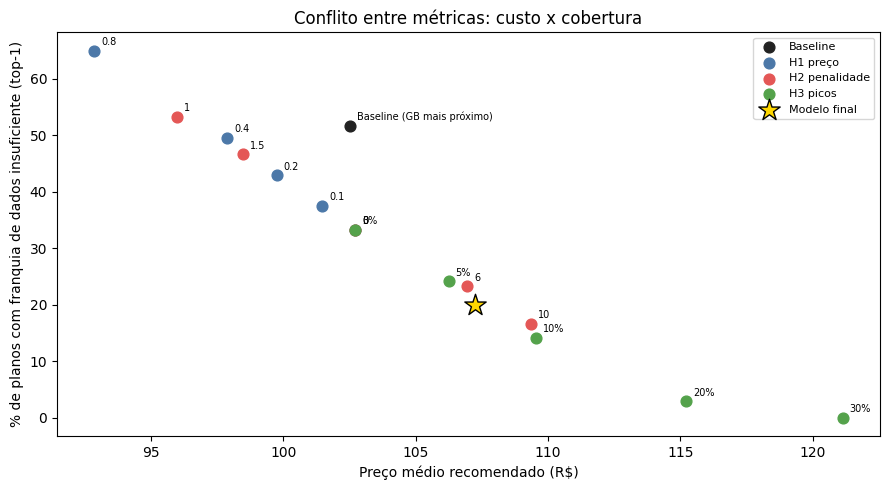

In [ ]:
# EDITE e justifique a sua escolha no relatório
CONFIG_FINAL = dict(penalidade_falta=3.0, margem_pico=0.10, peso_preco=0.20)

res_final = [
    avaliar('Baseline (GB mais próximo)', 'Comparação', top3_baseline(USO)),
    avaliar('Modelo final', 'Comparação', top3_modelo(USO, **CONFIG_FINAL)),
]
comparacao = pd.DataFrame(res_final).round(2).drop(columns='grupo').set_index('estrategia').T
display(comparacao)

# Gráfico do conflito preço x insuficiência (todos os experimentos)
fig, ax = plt.subplots(figsize=(9, 5))
cores = {'Baseline': '#222222', 'H2 penalidade': '#E45756', 'H1 preço': '#4C78A8', 'H3 picos': '#54A24B'}
for g, parte in tabela.groupby('grupo'):
    ax.scatter(parte['preco_medio_top1'], parte['pct_insuf_dados_top1'], label=g, color=cores[g], s=60)
    for _, r in parte.iterrows():
        ax.annotate(r['estrategia'].split('=')[-1], (r['preco_medio_top1'], r['pct_insuf_dados_top1']),
                    textcoords='offset points', xytext=(5, 4), fontsize=7)
final = comparacao['Modelo final']
ax.scatter(final['preco_medio_top1'], final['pct_insuf_dados_top1'], marker='*', s=260, color='gold', edgecolor='black', label='Modelo final')
ax.set_xlabel('Preço médio recomendado (R$)')
ax.set_ylabel('% de planos com franquia de dados insuficiente (top-1)')
ax.set_title('Conflito entre métricas: custo x cobertura')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**O que observar no gráfico:** o ideal está no **canto inferior esquerdo** (barato e sem insuficiência). Se os pontos formam uma "ladeira", reduzir insuficiência custa dinheiro: esse é o **trade-off** a discutir na apresentação.

## Etapa 9 — Estabilidade, sensibilidade, justiça e riscos

### 9.1 Estabilidade
Uma boa recomendação não deve mudar de forma radical por pequenos ajustes. Medimos:
- **Mudança de pesos:** % de clientes que continuam com a mesma recomendação nº 1 ao trocar os pesos.
- **Mudança de consumo:** o que acontece se todos os clientes passarem a consumir +10% ou +20%.

### 9.2 Justiça e exclusão digital
`idade_faixa` e `regiao` **não entram no modelo** (para não discriminar). Mesmo assim, o resultado pode afetar grupos de formas diferentes, então **auditamos** a recomendação por grupo.

### 9.3 Métrica complementar do grupo
`risco_cancelamento` também **não** entra no modelo. Usamos como indicador complementar: entre clientes de **maior risco**, a recomendação reduz a insuficiência de franquia?

In [ ]:
ref = top3_modelo(USO, **CONFIG_FINAL)[:, 0]

# 9.1a Mudança de pesos
PESOS_ALT = {
    'dados 55%':        {'dados_gb': .55, 'minutos': .15, 'streaming_horas': .15, 'deslocamento_dias': .15},
    'pesos iguais':     {'dados_gb': .25, 'minutos': .25, 'streaming_horas': .25, 'deslocamento_dias': .25},
    'foco streaming':   {'dados_gb': .30, 'minutos': .15, 'streaming_horas': .40, 'deslocamento_dias': .15},
    'foco mobilidade':  {'dados_gb': .30, 'minutos': .15, 'streaming_horas': .15, 'deslocamento_dias': .40},
}
est = []
for nome, p in PESOS_ALT.items():
    alt = top3_modelo(USO, pesos=p, **CONFIG_FINAL)[:, 0]
    est.append({'variação': nome, '% mesma recomendação': (alt == ref).mean() * 100,
                'preço médio (R$)': PRECOS[alt].mean()})
print('Estabilidade ao mudar os pesos (referência: PESOS atuais):')
display(pd.DataFrame(est).round(2).set_index('variação'))

# 9.1b Sensibilidade a mudanças de consumo
sens = []
for aumento in [0.10, 0.20]:
    novo = top3_modelo(USO * (1 + aumento), **CONFIG_FINAL)[:, 0]
    sens.append({'consumo': f'+{aumento:.0%}', '% mesma recomendação': (novo == ref).mean() * 100,
                 'preço médio (R$)': PRECOS[novo].mean(), 'variação de preço (R$)': PRECOS[novo].mean() - PRECOS[ref].mean()})
print('\nSensibilidade a aumento de consumo:')
display(pd.DataFrame(sens).round(2).set_index('consumo'))

# 9.2 / 9.3 Auditoria por grupo
exd_rec, _ = insuficiencia(USO, CATALOGO, ref)
seg = df[['regiao', 'idade_faixa', 'risco_cancelamento']].copy()
seg['atual_R$'] = ATUAL
seg['recomendado_R$'] = PRECOS[ref]
seg['insuf_dados_atual_%'] = df['excede_dados_atual'].to_numpy() * 100
seg['insuf_dados_recomendado_%'] = exd_rec * 100
for col in ['regiao', 'idade_faixa', 'risco_cancelamento']:
    print(f'\nAuditoria por {col}:')
    display(seg.groupby(col).agg(clientes=('atual_R$', 'size'), **{
        'atual_R$': ('atual_R$', 'mean'), 'recomendado_R$': ('recomendado_R$', 'mean'),
        'insuf_dados_atual_%': ('insuf_dados_atual_%', 'mean'),
        'insuf_dados_recomendado_%': ('insuf_dados_recomendado_%', 'mean')}).round(2))

Estabilidade ao mudar os pesos (referência: PESOS atuais):


,% mesma recomendação,preço médio (R$)
variação,,
dados 55%,83.75,106.11
pesos iguais,88.75,107.17
foco streaming,80.00,107.90
foco mobilidade,83.75,104.98



Sensibilidade a aumento de consumo:


,% mesma recomendação,preço médio (R$),variação de preço (R$)
consumo,,,
+10%,68.75,113.82,6.58
+20%,40.83,119.78,12.54



Auditoria por regiao:


,clientes,atual_R$,recomendado_R$,insuf_dados_atual_%,insuf_dados_recomendado_%
regiao,,,,,
periferica,88,88.42,107.34,61.36,25.00
rural,88,91.89,107.23,65.91,20.45
urbana,64,91.93,107.09,65.62,12.50



Auditoria por idade_faixa:


,clientes,atual_R$,recomendado_R$,insuf_dados_atual_%,insuf_dados_recomendado_%
idade_faixa,,,,,
18-25,67,86.54,109.97,67.16,20.90
26-40,51,92.15,107.06,70.59,29.41
41-60,57,90.86,107.79,68.42,22.81
60+,65,93.44,104.05,52.31,9.23



Auditoria por risco_cancelamento:


,clientes,atual_R$,recomendado_R$,insuf_dados_atual_%,insuf_dados_recomendado_%
risco_cancelamento,,,,,
0,141,105.18,105.29,50.35,19.15
1,99,69.90,110.00,83.84,21.21


### Riscos e limitações (cite no relatório e na apresentação)
- **Indicadores de laboratório:** medem coerência com um catálogo fictício, **não** satisfação real.
- **Exclusão digital:** se o modelo empurrar sistematicamente um grupo (ex.: `60+` ou região `rural`) para planos mais caros ou piores, há risco de exclusão. A auditoria acima serve para detectar isso; diferenças grandes entre grupos exigem revisão.
- **Uso indevido de atributos de perfil:** `idade_faixa` e `regiao` ficam **fora** do cálculo; só são usados para auditoria. O mesmo vale para `risco_cancelamento`.
- **Dado imputado:** 1 cliente teve `dados_gb` substituído pela mediana; a recomendação dele é aproximada (`dados_imputado = True`).
- **Rótulo `perfil_grupo`:** é igual para todos os clientes; não serve para separar perfis.
- **Validação humana:** a recomendação é um apoio; o atendente deve conferir catálogo vigente, contrato e elegibilidade.

## Etapa 10 — Explicação em português e interface

Esta etapa deixa o **motor de recomendação pronto para qualquer tela ou agente**. Ela entrega:

1. `validar_perfil(entrada)`: confere se os dados digitados são válidos (campos vazios, texto, negativos, valores absurdos) e **devolve uma mensagem clara** em vez de quebrar.
2. `recomendar_para_agente(entrada)`: devolve um **dicionário** (`ok`, `recomendacoes`, `aviso`...) fácil de ligar a Gradio, Streamlit, Chainlit, Flask/FastAPI ou a um agente de IA.
3. `explicar_recomendacao(entrada)`: transforma o resultado em **texto para o cliente**, com justificativa por plano e aviso de validação humana.

> 🔧 **Frontend/agente:** a tela final será construída conforme as instruções que você enviar. A célula do Gradio logo abaixo é apenas um **protótipo provisório** para o notebook já rodar de ponta a ponta.

In [ ]:
NOMES = {'dados_gb': ('Internet', 'GB'), 'minutos': ('Minutos de ligação', 'min'),
         'streaming_horas': ('Streaming', 'h'), 'deslocamento_dias': ('Deslocamento', 'dias')}
LIMITES_ENTRADA = {'dados_gb': (0, 300), 'minutos': (0, 5000), 'streaming_horas': (0, 200), 'deslocamento_dias': (0, 31)}
AVISO = 'Simulação educacional com catálogo fictício. A indicação precisa de validação humana (catálogo, contrato e elegibilidade).'

def validar_perfil(entrada):
    """Confere e converte a entrada. Levanta ValueError com mensagem clara se algo estiver errado."""
    perfil = {}
    for c, (lo, hi) in LIMITES_ENTRADA.items():
        nome, un = NOMES[c]
        v = entrada.get(c) if isinstance(entrada, dict) else None
        if v is None or (isinstance(v, float) and np.isnan(v)) or str(v).strip() == '':
            raise ValueError(f'informe o campo "{nome}" ({un}).')
        try:
            v = float(str(v).replace(',', '.'))
        except ValueError:
            raise ValueError(f'"{nome}" precisa ser um número (você digitou "{v}").')
        if not (lo <= v <= hi):
            raise ValueError(f'"{nome}" deve estar entre {lo} e {hi} {un} (você digitou {v:g}).')
        perfil[c] = v
    return perfil

def justificar(perfil, plano_nome):
    plano = CATALOGO.loc[CATALOGO['plano'] == plano_nome].iloc[0]
    cobre, falta = [], []
    for c in COLS_USO:
        nome, un = NOMES[c]
        uso, fr = perfil[c], float(plano[c])
        if uso <= fr:
            cobre.append(f'{nome}: cobre ({uso:g} de {fr:g} {un})')
        else:
            falta.append(f'{nome}: faltam {uso - fr:.1f} {un} (usa {uso:g}, plano tem {fr:g})')
    return cobre, falta

def recomendar_para_agente(entrada, k=3):
    """Função central para qualquer frontend/agente. Nunca levanta erro: devolve {'ok': False, 'erro': ...}."""
    try:
        perfil = validar_perfil(entrada)
    except ValueError as e:
        return {'ok': False, 'erro': str(e)}
    rec = recomendar(perfil, k=k, **CONFIG_FINAL)
    itens = []
    for i, r in rec.iterrows():
        cobre, falta = justificar(perfil, r['plano'])
        itens.append({'posicao': i + 1, 'plano': r['plano'], 'preco': float(r['preco']), 'score': float(r['score']),
                      'cobre_tudo': len(falta) == 0, 'cobre': cobre, 'nao_cobre': falta})
    return {'ok': True, 'perfil': perfil, 'recomendacoes': itens,
            'nenhum_cobre_tudo': not any(x['cobre_tudo'] for x in itens), 'aviso': AVISO}

def explicar_recomendacao(entrada, k=3):
    r = recomendar_para_agente(entrada, k)
    if not r['ok']:
        return f"⚠️ Não foi possível recomendar: {r['erro']}"
    p = r['perfil']
    linhas = [f"Perfil informado: {p['dados_gb']:g} GB, {p['minutos']:g} min, {p['streaming_horas']:g} h de streaming, {p['deslocamento_dias']:g} dias de deslocamento.", '']
    for x in r['recomendacoes']:
        status = 'cobre todas as necessidades' if x['cobre_tudo'] else 'NÃO cobre tudo'
        linhas.append(f"{x['posicao']}ª opção — {x['plano']} (R$ {x['preco']:.2f}/mês): {status}.")
        for t in x['cobre']:
            linhas.append(f'   ✔ {t}')
        for t in x['nao_cobre']:
            linhas.append(f'   ✖ {t}')
        linhas.append('')
    if r['nenhum_cobre_tudo']:
        linhas.append('Atenção: nenhum plano do catálogo cobre integralmente este perfil; indicamos os mais próximos.')
    linhas.append(r['aviso'])
    return '\n'.join(linhas)

# Testes: um caso normal, um extremo e entradas inválidas
print(explicar_recomendacao({'dados_gb': 48, 'minutos': 520, 'streaming_horas': 15, 'deslocamento_dias': 6}))
print('\n' + '-' * 60 + '\n')
print(explicar_recomendacao({'dados_gb': 200, 'minutos': 3000, 'streaming_horas': 80, 'deslocamento_dias': 25}))
print('\n' + '-' * 60 + '\n')
print(explicar_recomendacao({'dados_gb': None, 'minutos': 300, 'streaming_horas': 8, 'deslocamento_dias': 4}))
print(explicar_recomendacao({'dados_gb': 'abc', 'minutos': 300, 'streaming_horas': 8, 'deslocamento_dias': 4}))
print(explicar_recomendacao({'dados_gb': -5, 'minutos': 300, 'streaming_horas': 8, 'deslocamento_dias': 4}))

Perfil informado: 48 GB, 520 min, 15 h de streaming, 6 dias de deslocamento.

1ª opção — Max (R$ 109.90/mês): cobre todas as necessidades.
   ✔ Internet: cobre (48 de 55 GB)
   ✔ Minutos de ligação: cobre (520 de 700 min)
   ✔ Streaming: cobre (15 de 18 h)
   ✔ Deslocamento: cobre (6 de 8 dias)

2ª opção — Intenso (R$ 129.90/mês): cobre todas as necessidades.
   ✔ Internet: cobre (48 de 70 GB)
   ✔ Minutos de ligação: cobre (520 de 850 min)
   ✔ Streaming: cobre (15 de 22 h)
   ✔ Deslocamento: cobre (6 de 10 dias)

3ª opção — Digital (R$ 84.90/mês): NÃO cobre tudo.
   ✔ Deslocamento: cobre (6 de 6 dias)
   ✖ Internet: faltam 13.0 GB (usa 48, plano tem 35)
   ✖ Minutos de ligação: faltam 70.0 min (usa 520, plano tem 450)
   ✖ Streaming: faltam 3.0 h (usa 15, plano tem 12)

Simulação educacional com catálogo fictício. A indicação precisa de validação humana (catálogo, contrato e elegibilidade).

------------------------------------------------------------

Perfil informado: 200 GB, 3000 

### Protótipo provisório de tela (Gradio)
Este formulário apenas **demonstra** o motor. Ele será substituído/ajustado quando você definir como quer o frontend/agente. Execute no Colab; ele **não** envia dados a nenhum sistema comercial.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════════════════
# ATLANTIS — assistente de recomendação de planos

import subprocess, sys
from html import escape
from string import Template
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'gradio'], check=True)
    import gradio as gr

# ── Cores (inspiradas no vermelho da Claro) ──────────
PALETA = {'vermelho': '#DA291C', 'vermelho_escuro': '#A81C13', 'grafite': '#F8F9FA', 'cinza_fundo': '#212529',
          'cinza_borda': '#383E42', 'branco': '#121212', 'destaque': '#FFC72C', 'ok': '#28A745', 'texto_sec': '#E0E0E0'}

CAT = CATALOGO.set_index('plano')
ESC = {c: float(CATALOGO[c].max()) for c in COLS_USO}
SEM_ATUAL = 'Não informar'
NOVO_CLIENTE_OP = 'Novo cliente (digitar manual)'

def brl(v):  return 'R$ ' + f'{v:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
def numf(v): return f'{v:g}'.replace('.', ',')

CSS = Template("""
.atl-wrap{font-family:'Segoe UI',system-ui,-apple-system,Roboto,Arial,sans-serif;color:$grafite;line-height:1.6;background:$branco;border-radius:18px;padding:16px}
.atl-wrap *{box-sizing:border-box}
.atl-hero{background:linear-gradient(135deg,$vermelho,$vermelho_escuro);color:#fff;border-radius:18px;padding:22px 26px}
.atl-hero h1{margin:0;font-size:2.1rem;letter-spacing:-.5px;color:#fff}
.atl-hero p{margin:6px 0 0;font-size:1.05rem;color:#fff}
.atl-logo{display:flex;align-items:center;gap:14px}
.atl-mark{width:48px;height:48px;border-radius:50%;background:#fff;color:$vermelho;display:grid;place-items:center;font-weight:800;font-size:1.6rem;flex:none}
.atl-grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(270px,1fr));gap:16px;margin-top:14px}
.atl-card{background:$cinza_fundo;border:1px solid $cinza_borda;border-radius:18px;padding:18px;box-shadow:0 2px 8px rgba(0,0,0,.3);display:flex;flex-direction:column;gap:10px;color:$grafite}
.atl-card.atl-top{border:2px solid $vermelho}
.atl-card h3{margin:0;font-size:1.25rem;color:$grafite;font-weight:700}
.atl-head{display:flex;flex-wrap:wrap;align-items:center;gap:8px}
.atl-rank{background:$vermelho;color:#fff;border-radius:999px;padding:2px 12px;font-weight:700}
.atl-selo{background:$destaque;color:#111;border-radius:999px;padding:2px 12px;font-weight:700;font-size:.85rem}
.atl-fam{background:$cinza_fundo;border:1px solid $cinza_borda;border-radius:999px;padding:2px 10px;font-size:.85rem}
.atl-price{margin:0;font-size:1.9rem;font-weight:800;color:$vermelho}
.atl-price small{font-size:1rem;font-weight:600;color:$grafite}
.atl-muted{color:$texto_sec;font-size:0.98rem;margin:0;font-weight:500}
.atl-dim{display:grid;grid-template-columns:120px 1fr;gap:2px 10px;align-items:center;font-size:0.95rem;color:$grafite}
.atl-dim .atl-txt{grid-column:1 / -1;margin:0 0 4px 0;color:$texto_sec;font-weight:500}
.atl-bar{height:12px;border-radius:999px;background:#333;border:1px solid $cinza_borda;overflow:hidden}
.atl-bar div{height:100%;background:$ok}
.atl-bar.over div{background:repeating-linear-gradient(45deg,$vermelho,$vermelho 6px,$vermelho_escuro 6px,$vermelho_escuro 12px)}
.atl-bar.neutra div{background:$vermelho}
.atl-box{background:$cinza_fundo;border:1px solid $cinza_borda;border-radius:14px;padding:14px 16px;margin-top:14px;color:$grafite}
.atl-box h2,.atl-box h3{margin:0 0 6px;font-size:1.05rem;color:$grafite}
.atl-box ul{margin:6px 0 0 18px;padding:0;color:$grafite}
.atl-alert{background:#421515;border:2px solid $vermelho_escuro;border-radius:12px;padding:14px 16px;margin-top:12px;color:#ffdddd}
.atl-eco{font-weight:700;color:$grafite}
.atl-wrap details{border:1px solid $cinza_borda;border-radius:12px;padding:10px 14px;margin-top:10px;background:$cinza_fundo;color:$grafite}
.atl-wrap summary{cursor:pointer;font-weight:700;min-height:32px;color:$grafite}
.atl-wrap table{border-collapse:collapse;width:100%;font-size:.92rem;color:$grafite}
.atl-wrap th,.atl-wrap td{border:1px solid $cinza_borda;padding:6px 8px;text-align:left;color:$grafite}
.atl-wrap th{background:#2a3038}
.atl-scroll{overflow-x:auto}
#atl-buscar{background:$vermelho!important;color:#fff!important;border:none!important;min-height:48px;font-weight:700;font-size:1.05rem}
#atl-buscar:hover{background:$vermelho_escuro!important}
@media (max-width:600px){.atl-hero h1{font-size:1.7rem}.atl-price{font-size:1.6rem}.atl-dim{grid-template-columns:90px 1fr}}
""").substitute(**PALETA)

HTML_HERO = ('<div class="atl-wrap"><header class="atl-hero"><div class="atl-logo"><span class="atl-mark" aria-hidden="true">A</span>'
             '<div><h1>Atlantis</h1><p>Informe seu consumo e veja os 3 planos que melhor combinam com você, com a explicação de cada um.</p></div></div></header></div>')

def _dimensoes(perfil, plano):
    f = CAT.loc[plano]
    linhas = ''
    for c in COLS_USO:
        nome, un = NOMES[c]
        uso, fr = perfil[c], float(f[c])
        over = uso > fr
        pct = 100 if fr <= 0 else min(100, uso / fr * 100)
        txt = (f'{nome}: faltam {numf(uso - fr)} {un} (usa {numf(uso)}, plano tem {numf(fr)})' if over
               else f'{nome}: cobre ({numf(uso)} de {numf(fr)} {un})')
        icone = '✖' if over else '✔'
        linhas += (f'<div class="atl-dim"><span><strong>{escape(nome)}</strong></span>'
                   f'<div class="atl-bar{" over" if over else ""}" role="img" aria-label="{escape(txt)}"><div style="width:{pct:.0f}%"></div></div>'
                   f'<span class="atl-txt">{icone} {escape(txt)}</span></div>')
    return linhas

def _economia(preco, atual):
    if atual in (None, SEM_ATUAL) or atual not in CAT.index:
        return ''
    dif = preco - float(CAT.loc[atual, 'preco'])
    if abs(dif) < 0.005:
        return f'<p class="atl-eco">Mesmo valor do seu plano atual ({escape(atual)}).</p>'
    if dif < 0:
        return f'<p class="atl-eco">Você economiza {brl(-dif)} por mês em relação ao {escape(atual)}.</p>'
    return f'<p class="atl-eco">Você pagaria {brl(dif)} a mais por mês em relação ao {escape(atual)}.</p>'

def card_recomendacao(x, perfil, atual, selos):
    s = ''.join(f'<span class="atl-selo">★ {escape(t)}</span>' for t in selos)
    status = 'Cobre todas as suas necessidades' if x['cobre_tudo'] else 'NÃO cobre tudo'
    return (f'<article class="atl-card{" atl-top" if x["posicao"] == 1 else ""}" aria-label="{x["posicao"]}ª opção: {escape(x["plano"])}">'
            f'<div class="atl-head"><span class="atl-rank">{x["posicao"]}ª opção</span>{s}</div>'
            f'<h3>{escape(x["plano"])}</h3><p class="atl-price">{brl(x["preco"])}<small>/mês</small></p>'
            f'<p class="atl-muted"><strong>{status}</strong></p>{_economia(x["preco"], atual)}{_dimensoes(perfil, x["plano"])}</article>')

def _bloco_baseline(perfil, rec):
    base = baseline_plano(perfil)
    linhas, cobre_base = '', 0
    for _, b in base.iterrows():
        cobre = all(perfil[c] <= float(b[c]) for c in COLS_USO)
        cobre_base += cobre
        linhas += (f'<tr><td>{escape(str(b["plano"]))}</td><td>{brl(float(b["preco"]))}</td>'
                   f'<td>{"✔ cobre tudo" if cobre else "✖ não cobre tudo"}</td></tr>')
    cobre_mod = sum(x['cobre_tudo'] for x in rec)
    return ('<details><summary>Compare com a regra simples (baseline da Etapa 6)</summary>'
            f'<p>A regra simples olha só os GB de internet. Nas 3 opções dela, <strong>{cobre_base} de {len(base)}</strong> cobrem tudo; '
            f'nas 3 opções do Atlantis, <strong>{cobre_mod} de {len(rec)}</strong>.</p>'
            '<div class="atl-scroll"><table><caption>Opções da regra simples</caption><thead><tr><th scope="col">Plano</th><th scope="col">Preço</th><th scope="col">Cobertura</th></tr></thead>'
            f'<tbody>{linhas}</tbody></table></div></details>')

def html_resultado(r, atual=SEM_ATUAL):
    if not r['ok']:
        return f'<div class="atl-wrap"><div class="atl-alert" role="alert"><strong>Quase lá!</strong> {escape(r["erro"])}</div></div>'
    p, rec = r['perfil'], r['recomendacoes']
    cobrem = [x for x in rec if x['cobre_tudo']]
    barato = min(cobrem, key=lambda x: x['preco'])['plano'] if cobrem else None
    pedido = ''.join(f'<li>{escape(NOMES[c][0])}: <strong>{numf(p[c])} {NOMES[c][1]}</strong></li>' for c in COLS_USO)
    aviso = ('<div class="atl-alert" role="alert"><strong>Atenção:</strong> nenhum plano do catálogo cobre integralmente este perfil; '
             'mostramos os mais próximos.</div>') if r['nenhum_cobre_tudo'] else ''
    cards = ''.join(card_recomendacao(x, p, atual, (['Melhor equilíbrio'] if x['posicao'] == 1 else []) +
                                                  (['Menor preço que cobre tudo'] if x['plano'] == barato else [])) for x in rec)
    return (f'<div class="atl-wrap" aria-live="polite"><h2 style="margin:0 0 6px">Suas 3 melhores opções</h2>'
            f'<div class="atl-box"><h3>Perfil informado</h3><ul>{pedido}</ul></div>{aviso}<div class="atl-grid">{cards}</div>'
            f'{_bloco_baseline(p, rec)}<p class="atl-muted" style="margin-top:12px">{escape(r["aviso"])}</p></div>')

def html_catalogo(ordem='Menor preço'):
    df_c = CATALOGO.sort_values('preco') if ordem == 'Menor preço' else CATALOGO.sort_values('dados_gb', ascending=False)
    cards = ''
    for _, p in df_c.iterrows():
        dims = ''
        for c in COLS_USO:
            nome, un = NOMES[c]
            pct = min(100, float(p[c]) / ESC[c] * 100)
            dims += (f'<div class="atl-dim"><span><strong>{escape(nome)}</strong></span>'
                     f'<div class="atl-bar neutra" role="img" aria-label="{escape(nome)}: {numf(float(p[c]))} {un}"><div style="width:{pct:.0f}%"></div></div>'
                     f'<span class="atl-txt">{numf(float(p[c]))} {un}</span></div>')
        cards += (f'<article class="atl-card" aria-label="{escape(str(p["plano"]))}"><h3>{escape(str(p["plano"]))}</h3>'
                  f'<p class="atl-price">{brl(float(p["preco"]))}<small>/mês</small></p>{dims}</article>')
    return f'<div class="atl-wrap"><p class="atl-muted">{len(df_c)} planos do catálogo (fictício) da Etapa 4.</p><div class="atl-grid">{cards}</div></div>'

def html_como_funciona():
    cfg = CONFIG_FINAL
    pesos = ''.join(f'<li>{escape(NOMES[c][0])}: {PESOS[c]:.0%}</li>' for c in COLS_USO)
    return (f'<div class="atl-wrap"><h2 style="margin:0 0 6px">Como o Atlantis decide</h2>'
            '<p>É o modelo final das Etapas 7 a 9, sem alterações. Cada plano recebe uma nota e <strong>quanto menor, melhor</strong>.</p>'
            f'<div class="atl-box"><h3>Configuração em uso</h3><ul><li>Faltar franquia pesa <strong>{numf(cfg["penalidade_falta"])}×</strong> mais do que sobrar.</li>'
            f'<li>Margem para picos de consumo: <strong>{cfg["margem_pico"]:.0%}</strong>.</li><li>Peso do preço na nota: <strong>{numf(cfg["peso_preco"])}</strong>.</li></ul>'
            f'<h3 style="margin-top:10px">Pesos por atributo</h3><ul>{pesos}</ul></div>'
            '<p style="margin-top:10px"><code>score = √( Σ peso × penalidade × diferença_normalizada² ) + peso_preco × (preço / preço_máximo)</code></p>'
            '<p>Para dizer se um plano “cobre” ou “não cobre”, o Atlantis usa o consumo <strong>real</strong>, sem a margem de picos.</p>'
            f'<p class="atl-muted">{escape(AVISO)}</p></div>')

def estilo_acessivel(tamanho, contraste, reduzir):
    escala = {'Normal': 100, 'Grande': 118, 'Muito grande': 135}[tamanho]
    css = f'.atl-wrap{{font-size:{escala}%}}'
    if contraste:
        css += ('.atl-wrap{color:#000!important;background:#fff!important}.atl-muted,.atl-dim .atl-txt{color:#000!important}.atl-card,.atl-box,.atl-wrap details{border:2px solid #000!important;background:#fff!important}'
                '.atl-hero{background:#000!important}.atl-price{color:#000!important}')
    if reduzir:
        css += '*{animation:none!important;transition:none!important;scroll-behavior:auto!important}'
    return f'<style>{css}</style>'

def ui_recomendar(dados, minutos, streaming, desloc, atual):
    entrada = {'dados_gb': dados, 'minutos': minutos, 'streaming_horas': streaming, 'deslocamento_dias': desloc}
    return html_resultado(recomendar_para_agente(entrada, 3), atual)

TEM_BASE = 'df' in globals() and {'id_cliente', 'plano_atual'}.issubset(df.columns)

def ui_carregar_cliente(id_cliente):
    if id_cliente == NOVO_CLIENTE_OP or not id_cliente:
        # Retorna valores padrão vazios/zerados para digitação manual de um novo cliente
        return [40.0, 500.0, 15.0, 5.0, SEM_ATUAL]
    try:
        linha = df[df['id_cliente'].astype(str) == str(id_cliente)].iloc[0]
        return [float(linha[c]) for c in COLS_USO] + [linha['plano_atual']]
    except Exception:
        return [gr.update()] * 5

with gr.Blocks(title='Atlantis · Recomendador de planos', theme=gr.themes.Base()) as atlantis:
    gr.HTML(f'<style>{CSS}.sr-only{{position:absolute;width:1px;height:1px;overflow:hidden;clip:rect(0,0,0,0)}}</style>')
    estilo = gr.HTML(estilo_acessivel('Normal', False, False))
    gr.HTML(HTML_HERO)
    with gr.Tabs():
        with gr.Tab('🔎 Encontrar meu plano'):
            with gr.Row():
                with gr.Column(scale=2, min_width=320):
                    if TEM_BASE:
                        opcoes_cliente = [NOVO_CLIENTE_OP] + list(df['id_cliente'].astype(str).head(40))
                        cliente = gr.Dropdown(opcoes_cliente, value=NOVO_CLIENTE_OP, label='Selecionar Cliente ou Inserir Novo',
                                              info='Escolha um cliente da base ou selecione "Novo cliente" para digitar manualmente.')
                    dados = gr.Number(value=40, label=f'{NOMES["dados_gb"][0]} ({NOMES["dados_gb"][1]}/mês)', info='Valor entre 0 e 300.')
                    minutos = gr.Number(value=500, label=f'{NOMES["minutos"][0]} ({NOMES["minutos"][1]}/mês)', info='Valor entre 0 e 5000.')
                    streaming = gr.Number(value=15, label=f'{NOMES["streaming_horas"][0]} ({NOMES["streaming_horas"][1]}/mês)', info='Valor entre 0 e 200.')
                    desloc = gr.Number(value=5, label=f'{NOMES["deslocamento_dias"][0]} ({NOMES["deslocamento_dias"][1]}/mês)', info='Valor entre 0 e 31.')
                    atual = gr.Dropdown([SEM_ATUAL] + list(CATALOGO['plano']), value=SEM_ATUAL, label='Seu plano atual (opcional)',
                                        info='Se informar, mostramos quanto você economiza ou paga a mais.')
                    buscar = gr.Button('Ver minhas opções', elem_id='atl-buscar')
                with gr.Column(scale=3, min_width=320):
                    saida = gr.HTML()
            entradas = [dados, minutos, streaming, desloc, atual]
            buscar.click(ui_recomendar, entradas, saida)
            atlantis.load(ui_recomendar, entradas, saida)
            if TEM_BASE:
                cliente.change(ui_carregar_cliente, inputs=cliente, outputs=entradas)
        with gr.Tab('📋 Catálogo de planos'):
            ordem = gr.Radio(['Menor preço', 'Mais internet'], value='Menor preço', label='Ordenar por')
            cat_html = gr.HTML(html_catalogo())
            ordem.change(html_catalogo, ordem, cat_html)
        with gr.Tab('🧠 Como funciona'):
            gr.HTML(html_como_funciona())
        with gr.Tab('♿ Acessibilidade'):
            gr.HTML('<div class="atl-wrap"><p>Ajuste a leitura do Atlantis. Tudo funciona só com teclado (Tab, setas, Enter) e as barras têm texto alternativo para leitores de tela.</p></div>')
            tam = gr.Radio(['Normal', 'Grande', 'Muito grande'], value='Normal', label='Tamanho da letra')
            contr = gr.Checkbox(label='Alto contraste')
            red = gr.Checkbox(label='Reduzir animações')
            for c in (tam, contr, red):
                c.change(estilo_acessivel, [tam, contr, red], estilo)

atlantis.launch(share=False, debug=False)

/tmp/ipykernel_520/3066289524.py:186: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title='Atlantis · Recomendador de planos', theme=gr.themes.Base()) as atlantis:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>